# LLM query router: full-data demo

- Router: per question, cheap Llama 3.1 8B or expensive Llama 3.3 70B?
- Goal: most questions answered cheaply, little accuracy lost
- Data: all 17,032 MATH + MMLU-Pro test questions
- Routers: MLP probe, linear probe

1. The data
2. Embeddings
3. Training the probes
4. Predicting correctness
5. Routing a question
6. Accuracy-vs-cost curves
7. Choosing an operating point
8. Failure analysis

In [1]:
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

sys.path.insert(0, '..')
import mlp_probe as mp
import linear_probe as lp

%matplotlib inline
pd.set_option('display.max_colwidth', 120)

## 1. The data

- Both models answered every question once
- Per question: 8B right/wrong, 70B right/wrong, cost of each

In [2]:
df = mp.load()
C = df[mp.MODELS].to_numpy(int)
K = df[[f'cost_{m}' for m in mp.MODELS]].to_numpy(float)
L = df[[f'latency_{m}' for m in mp.MODELS]].to_numpy(float)
print(f'{len(df):,} questions:', df.dataset.value_counts().to_dict())
df[['dataset', 'subject', 'llama-8b', 'llama-70b', 'cost_llama-8b', 'cost_llama-70b']].head()

17,032 questions: {'mmlupro': 12032, 'math': 5000}


,dataset,subject,llama-8b,llama-70b,cost_llama-8b,cost_llama-70b
qid,,,,,,
math_0,math,Intermediate Algebra,0,1,0.000008,0.000107
math_1,math,Counting & Probability,0,0,0.000008,0.000143
math_10,math,Precalculus,0,0,0.000022,0.000329
math_100,math,Intermediate Algebra,1,1,0.000011,0.000235
math_1000,math,Algebra,0,1,0.000006,0.000105


- 4 groups per question
- Only "only 70B solves" is worth paying for
- "Neither solves" -> 8B (no router can help)

In [3]:
c, e = df['llama-8b'], df['llama-70b']
groups = pd.Series(np.select([(c == 1) & (e == 1), (c == 1) & (e == 0), (c == 0) & (e == 1)],
                             ['both solve', 'only 8B solves', 'only 70B solves'], 'neither solves'),
                   index=df.index, name='group')
pd.crosstab(df.dataset, groups, normalize='index', margins=True).round(3)

group,both solve,neither solves,only 70B solves,only 8B solves
dataset,,,,
math,0.320,0.246,0.417,0.017
mmlupro,0.374,0.269,0.306,0.051
All,0.359,0.262,0.339,0.041


- Oracle = perfect router
- Cheapest correct model; 8B if neither is correct

In [4]:
n_all = len(df)
base_all = {
    'always 8B': mp.metrics(np.zeros(n_all, int), C, K, L),
    'always 70B': mp.metrics(np.ones(n_all, int), C, K, L),
    'oracle': mp.metrics(mp.oracle_choice(C), C, K, L),
}
pd.DataFrame(base_all).T[['task_acc', 'cost_frac', 'frac_llama-70b', 'latency_s']].round(3)

,task_acc,cost_frac,frac_llama-70b,latency_s
always 8B,0.399,0.154,0.000,14.870
always 70B,0.697,1.000,1.000,21.564
oracle,0.738,0.447,0.339,15.864


- `cost_frac` = cost / always-70B cost
- Target: within 3 pts of always-70B, <= 40% of its cost
- Oracle needs ~44% -> target out of reach even for a perfect router
- So also compare: distance to the oracle curve

## 2. Embeddings

- Frozen `all-MiniLM-L6-v2` -> 384 numbers per question
- Only the probe on top is trained

In [5]:
X = mp.embeddings(df)
print('embedding matrix:', X.shape)
example = df.index[0]
print(f'\n{example} ({df.dataset[example]}):\n{df.text[example][:300]}')
print('\nfirst 8 of its 384 numbers:', np.round(X[0, :8], 3))

embedding matrix: (17032, 384)

math_0 (math):
If $y=\frac{27x^2+9x+3}{27x^3+9x^2+3x+1}$, at what value of $y$ will there be a horizontal asymptote?

first 8 of its 384 numbers: [-0.024  0.018 -0.04   0.043  0.022  0.032 -0.086  0.049]


- PCA of 3,000 random questions
- Separates by dataset (topic)
- Groups (difficulty) all mixed

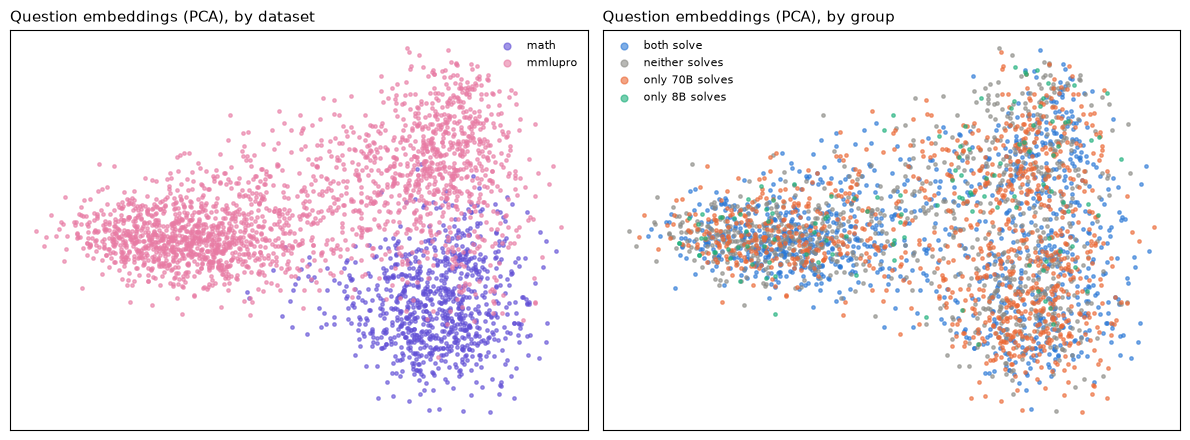

In [6]:
from sklearn.decomposition import PCA

xy = PCA(2, random_state=0).fit_transform(X)
show = np.random.default_rng(0).choice(len(df), 3000, replace=False)
colors = {'both solve': '#2a78d6', 'only 8B solves': '#1baf7a', 'only 70B solves': '#eb6834',
          'neither solves': '#8a8a85', 'math': '#6250d6', 'mmlupro': '#e87ba4'}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (title, key) in zip(axes, [('by dataset', df.dataset), ('by group', groups)]):
    k = key.to_numpy()[show]
    for lab in sorted(set(k)):
        pts = xy[show][k == lab]
        ax.scatter(pts[:, 0], pts[:, 1], s=6, alpha=0.6, label=lab, color=colors[lab])
    ax.set_title(f'Question embeddings (PCA), {title}', loc='left', fontsize=11)
    ax.set_xticks([]); ax.set_yticks([])
    ax.legend(frameon=False, fontsize=8, markerscale=2)
plt.tight_layout()

## 3. Training the probes

- Split 60/20/20 train/val/test, stratified by dataset
- Output: P(8B correct), P(70B correct)
- Loss: BCE summed over both models; Adam
- MLP: 384 -> hidden -> 2, early stopping, 3 seeds, hyperparameters from `mlp_probe.py`
- Linear: 384 -> 2, weight decay picked on val

In [7]:
S = {s: (df.split == s).to_numpy() for s in mp.SPLIT}
tr, va, te = S['train'], S['val'], S['test']
print({s: int(m.sum()) for s, m in S.items()})

mu, sd = X[tr].mean(0), X[tr].std(0) + 1e-6
Z = (X - mu) / sd

hp = json.loads((mp.OUT / 'summary.json').read_text())['hyperparameters']
print('MLP hyper-parameters:', hp)
nets = [mp.train(Z[tr], C[tr], Z[va], C[va], seed=s, **hp)[0] for s in mp.SEEDS]


def val_bce(wd):
    p = np.clip(lp.predict(lp.train(Z[tr], C[tr], wd), Z[va]), 1e-6, 1 - 1e-6)
    return -(C[va] * np.log(p) + (1 - C[va]) * np.log(1 - p)).sum(1).mean()


wd = min(lp.WEIGHT_DECAYS, key=val_bce)
print('linear weight decay:', wd)
linear = lp.train(Z[tr], C[tr], wd)

probs = {'MLP': mp.predict(nets, Z), 'Linear': lp.predict(linear, Z)}

{'train': 10219, 'val': 3406, 'test': 3407}
MLP hyper-parameters: {'hidden': 32, 'lr': 0.003, 'weight_decay': 0.001, 'dropout': 0.3}


linear weight decay: 0.01


Sample test predictions:

In [8]:
preview = df.loc[te, ['dataset', 'subject', 'llama-8b', 'llama-70b']].copy()
for name, P in probs.items():
    preview[f'{name} P(8B)'] = P[te, 0].round(2)
    preview[f'{name} P(70B)'] = P[te, 1].round(2)
preview.head(10)

,dataset,subject,llama-8b,llama-70b,MLP P(8B),MLP P(70B),Linear P(8B),Linear P(70B)
qid,,,,,,,,
math_100,math,Intermediate Algebra,1,1,0.20,0.73,0.22,0.80
math_1002,math,Algebra,1,1,0.57,0.98,0.45,0.94
math_1004,math,Counting & Probability,1,1,0.31,0.77,0.25,0.72
math_1005,math,Algebra,1,1,0.49,0.91,0.43,0.87
math_1011,math,Prealgebra,1,1,0.65,0.92,0.55,0.90
math_1014,math,Counting & Probability,1,1,0.67,0.95,0.52,0.90
math_1018,math,Algebra,0,0,0.38,0.83,0.39,0.78
math_1021,math,Precalculus,0,0,0.37,0.82,0.30,0.88
math_1027,math,Prealgebra,0,1,0.84,0.99,0.68,0.95


## 4. Predicting correctness

- Test AUROC per head, overall + per dataset
- Subject-only baseline: model's train accuracy on that subject

In [9]:
Ct, Kt, Lt = C[te], K[te], L[te]
n = len(Ct)
subject_acc = df[tr].groupby(['dataset', 'subject'])[mp.MODELS].mean()
P_subject = subject_acc.loc[list(zip(df.dataset[te], df.subject[te]))].to_numpy()

rows = {}
for name, Pt in [('MLP', probs['MLP'][te]), ('Linear', probs['Linear'][te]), ('Subject only', P_subject)]:
    r = {}
    for j, m in enumerate(mp.MODELS):
        r[f'{m} head'] = roc_auc_score(Ct[:, j], Pt[:, j])
        for d in ('math', 'mmlupro'):
            s = (df.dataset[te] == d).to_numpy()
            r[f'{m} head, {d}'] = roc_auc_score(Ct[s, j], Pt[s, j])
    rows[name] = r
pd.DataFrame(rows).T.round(3)

,llama-8b head,"llama-8b head, math","llama-8b head, mmlupro",llama-70b head,"llama-70b head, math","llama-70b head, mmlupro"
MLP,0.682,0.742,0.650,0.701,0.797,0.650
Linear,0.662,0.721,0.632,0.683,0.782,0.633
Subject only,0.642,0.685,0.605,0.636,0.683,0.600


- Both probes beat subject-only, most on MATH
- But routing needs: which questions only the 70B solves
- Score = predicted gain P(70B) - P(8B):

In [10]:
only_70b = (Ct[:, 0] == 0) & (Ct[:, 1] == 1)
pd.Series({name: roc_auc_score(only_70b, P[te, 1] - P[te, 0]) for name, P in probs.items()},
          name='AUROC of predicted gain for "only 70B solves"').round(3).to_frame()

,"AUROC of predicted gain for ""only 70B solves"""
MLP,0.597
Linear,0.584


## 5. Routing a question

- Threshold rule: P(8B) > t -> 8B, else 70B (t: 0 to 1)
- Gain rule: P(70B) - P(8B) > t -> 70B, else 8B (t: -1 to 1)
- Example: one test question, MLP probe

In [11]:
P = probs['MLP']
q = df.index[te][0]
i = df.index.get_loc(q)
print(df.text[q][:400], '\n')
print(f'P(8B correct) = {P[i, 0]:.2f}   P(70B correct) = {P[i, 1]:.2f}   gain = {P[i, 1] - P[i, 0]:+.2f}')
print(f"truth: 8B {'right' if C[i, 0] else 'wrong'}, 70B {'right' if C[i, 1] else 'wrong'}\n")
for t in (0.2, 0.4, 0.6, 0.8):
    print(f'threshold rule, t = {t:.1f} -> {mp.MODELS[mp.route(P[i:i + 1], t)[0]]}')
print()
for t in (0.0, 0.2, 0.4, 0.6):
    print(f'gain rule,      t = {t:+.1f} -> {mp.MODELS[mp.route_gain(P[i:i + 1], t)[0]]}')

Find all the integer roots of
\[2x^3 + 13x^2 - 23x + 8 = 0.\]Enter all the integer roots, separated by commas. 

P(8B correct) = 0.20   P(70B correct) = 0.73   gain = +0.53
truth: 8B right, 70B right

threshold rule, t = 0.2 -> llama-8b
threshold rule, t = 0.4 -> llama-70b
threshold rule, t = 0.6 -> llama-70b
threshold rule, t = 0.8 -> llama-70b

gain rule,      t = +0.0 -> llama-70b
gain rule,      t = +0.2 -> llama-70b
gain rule,      t = +0.4 -> llama-70b
gain rule,      t = +0.6 -> llama-8b


## 6. Accuracy-vs-cost curves

- Sweep t: always-8B -> always-70B
- Good router: climbs steeply toward the oracle
- Baselines: random (20 seeds), length (longest -> 70B first)

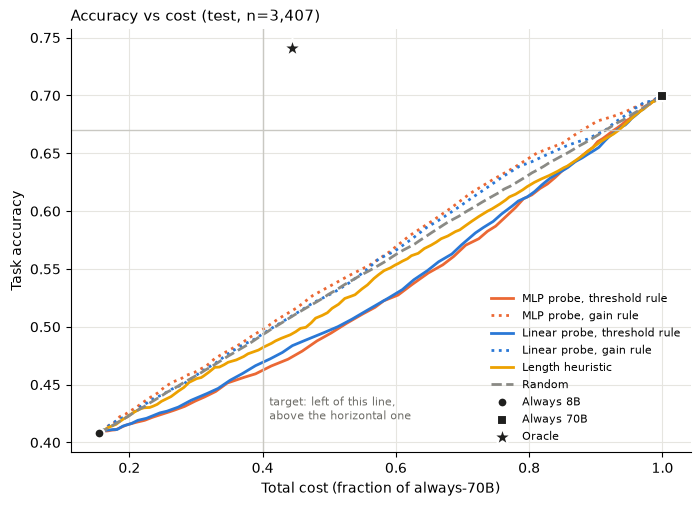

In [12]:
rules = {'threshold rule': (mp.route, None), 'gain rule': (mp.route_gain, mp.GAIN_TS)}
curves = {(name, rule): mp.sweep(P[te], Ct, Kt, Lt, rule=fn, ts=ts)
          for name, P in probs.items() for rule, (fn, ts) in rules.items()}
rand = pd.concat([mp.sweep(np.random.default_rng(s).uniform(size=(n, 2)), Ct, Kt, Lt)
                  for s in range(20)]).groupby('t', as_index=False).mean()
train_len = np.sort(df.text[tr].str.len().to_numpy())
pct = np.searchsorted(train_len, df.text[te].str.len().to_numpy(), side='right') / (len(train_len) + 1)
length = mp.sweep(np.stack([1 - pct, np.ones(n)], 1), Ct, Kt, Lt)
base = {'always_cheapest': mp.metrics(np.zeros(n, int), Ct, Kt, Lt),
        'always_most_expensive': mp.metrics(np.ones(n, int), Ct, Kt, Lt),
        'oracle': mp.metrics(mp.oracle_choice(Ct), Ct, Kt, Lt)}

fig, ax = plt.subplots(figsize=(8, 5.5))
for (name, rule), cv in curves.items():
    ax.plot(cv.cost_frac, cv.task_acc, lw=2, color='#eb6834' if name == 'MLP' else '#2a78d6',
            ls='-' if rule == 'threshold rule' else ':', label=f'{name} probe, {rule}')
ax.plot(length.cost_frac, length.task_acc, color='#eda100', lw=2, label='Length heuristic')
ax.plot(rand.cost_frac, rand.task_acc, color='#8a8a85', lw=2, ls='--', label='Random')
for name, marker, label in [('always_cheapest', 'o', 'Always 8B'), ('always_most_expensive', 's', 'Always 70B'),
                            ('oracle', '*', 'Oracle')]:
    ax.scatter(base[name]['cost_frac'], base[name]['task_acc'], marker=marker, s=200 if marker == '*' else 50,
               color='#1f1f1e', edgecolor='white', lw=1.5, zorder=5, label=label)
ax.axvline(mp.TARGET_COST, color='#c9c8c2', lw=1)
ax.axhline(base['always_most_expensive']['task_acc'] - mp.TARGET_GAP / 100, color='#c9c8c2', lw=1)
ax.text(mp.TARGET_COST + 0.01, 0.42, 'target: left of this line,\nabove the horizontal one',
        fontsize=8, color='#6e6d68')
ax.set_xlabel('Total cost (fraction of always-70B)')
ax.set_ylabel('Task accuracy')
ax.set_title(f'Accuracy vs cost (test, n={n:,})', loc='left', fontsize=11)
ax.grid(True, color='#e6e5e0'); ax.set_axisbelow(True)
for s in ('top', 'right'):
    ax.spines[s].set_visible(False)
ax.legend(frameon=False, fontsize=8, loc='lower right');

Gap to oracle curve (lower = better), best accuracy at <= 40% cost:

In [13]:
def at_40(cv):
    return cv[cv.cost_frac <= mp.TARGET_COST].task_acc.max()


summary = {f'{name} probe, {rule}': (mp.oracle_gap(cv, Ct, Kt), at_40(cv)) for (name, rule), cv in curves.items()}
summary['Length heuristic'] = (mp.oracle_gap(length, Ct, Kt), at_40(length))
summary['Random'] = (mp.oracle_gap(rand, Ct, Kt), at_40(rand))
pd.DataFrame(summary, index=['gap to oracle curve', 'best acc at <=40% cost']).T.round(3)

,gap to oracle curve,best acc at <=40% cost
"MLP probe, threshold rule",0.154,0.459
"MLP probe, gain rule",0.126,0.491
"Linear probe, threshold rule",0.152,0.466
"Linear probe, gain rule",0.129,0.489
Length heuristic,0.139,0.480
Random,0.131,0.493


## 7. Choosing an operating point

- t = cheapest within 3 pts of always-70B on val
- Applied unchanged to test
- (`linear_probe.py` picks on test -> its own numbers slightly optimistic)

In [14]:
acc_exp_val = C[va, 1].mean()
points = {}
for name, P in probs.items():
    for rule, (fn, ts) in rules.items():
        t = mp.pick_t(mp.sweep(P[va], C[va], K[va], L[va], rule=fn, ts=ts), acc_exp_val)
        m = mp.metrics(fn(P[te], t), Ct, Kt, Lt)
        gap = 100 * (base['always_most_expensive']['task_acc'] - m['task_acc'])
        points[f'{name} probe, {rule}'] = {
            't*': t, 'test acc': m['task_acc'], 'gap to 70B (pts)': gap, 'cost frac': m['cost_frac'],
            'sent to 70B': m['frac_llama-70b'], 'routing acc': m['routing_acc'],
            'meets target': gap <= mp.TARGET_GAP and m['cost_frac'] <= mp.TARGET_COST}
pd.DataFrame(points).T

,t*,test acc,gap to 70B (pts),cost frac,sent to 70B,routing acc,meets target
"MLP probe, threshold rule",0.59,0.665982,3.375404,0.917975,0.840622,0.418257,False
"MLP probe, gain rule",0.18,0.681832,1.790431,0.925298,0.88641,0.398298,False
"Linear probe, threshold rule",0.6,0.666862,3.28735,0.925219,0.84708,0.412386,False
"Linear probe, gain rule",0.13,0.676255,2.348107,0.927461,0.877605,0.39595,False


## 8. Failure analysis

- MLP, threshold rule, at chosen t
- Optimal: same as oracle
- Under-routed: -> 8B, only 70B solves (accuracy lost)
- Over-routed: -> 70B, 8B solves (money wasted)
- No model solves

In [15]:
P = probs['MLP']
t_star = points['MLP probe, threshold rule']['t*']
ch, orc = mp.route(P[te], t_star), mp.oracle_choice(Ct)
outcome = pd.Series(np.select([~Ct.any(1), ch == orc, ch < orc],
                              ['no model solves', 'optimal', 'under-routed'], 'over-routed'),
                    index=df.index[te], name='outcome')
pd.crosstab(df.dataset[te], outcome, margins=True)

outcome,no model solves,optimal,over-routed,under-routed,All
dataset,,,,,
math,249,481,224,46,1000
mmlupro,634,898,795,80,2407
All,883,1379,1019,126,3407


- Average predictions by true group
- Probes learn one difficulty score: hard for 8B ~ hard for 70B
- Hardest-looking = "neither solves" -> threshold rule spends on these first -> worse than random
- "Only 70B solves" sits mid-difficulty; predicted gain barely separates it

In [16]:
g_te = groups[te].to_numpy()
order = ['both solve', 'only 8B solves', 'only 70B solves', 'neither solves']
tables = []
for name, P in probs.items():
    t = pd.DataFrame({'P(8B)': P[te, 0], 'P(70B)': P[te, 1], 'gain': P[te, 1] - P[te, 0], 'group': g_te})
    tables.append(t.groupby('group').mean().loc[order].add_prefix(f'{name} '))
pd.concat([pd.Series(g_te).value_counts().loc[order].rename('n')] + tables, axis=1).round(3)

,n,MLP P(8B),MLP P(70B),MLP gain,Linear P(8B),Linear P(70B),Linear gain
both solve,1250,0.488,0.766,0.278,0.476,0.744,0.268
only 8B solves,140,0.381,0.647,0.265,0.386,0.639,0.253
only 70B solves,1134,0.392,0.705,0.314,0.389,0.696,0.307
neither solves,883,0.341,0.621,0.280,0.343,0.617,0.274


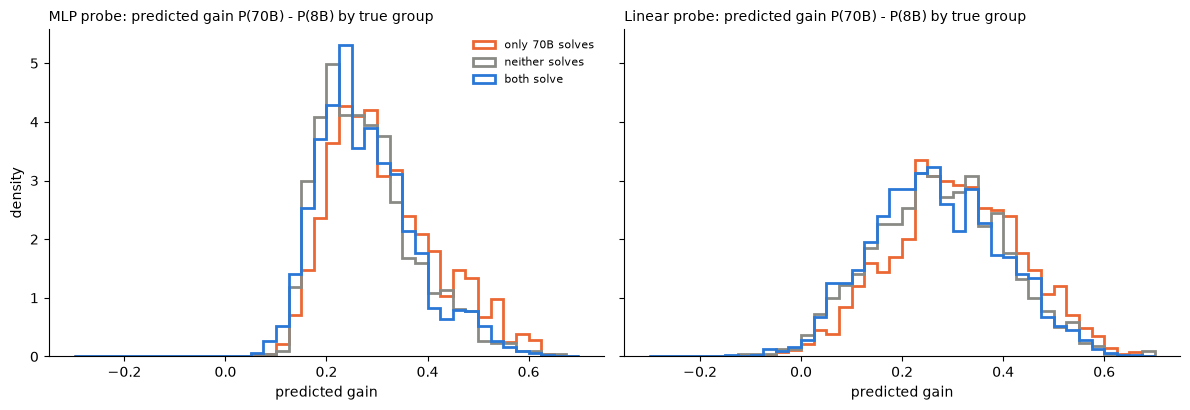

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
bins = np.linspace(-0.3, 0.7, 41)
for ax, (name, P) in zip(axes, probs.items()):
    gain = P[te, 1] - P[te, 0]
    for g in ('only 70B solves', 'neither solves', 'both solve'):
        ax.hist(gain[g_te == g], bins=bins, density=True, histtype='step', lw=2, color=colors[g], label=g)
    ax.set_title(f'{name} probe: predicted gain P(70B) - P(8B) by true group', loc='left', fontsize=10)
    ax.set_xlabel('predicted gain')
    for s in ('top', 'right'):
        ax.spines[s].set_visible(False)
axes[0].set_ylabel('density')
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()

Over-routed examples (8B was right):

In [18]:
P = probs['MLP']
for q in outcome[outcome == 'over-routed'].index[:3]:
    i = df.index.get_loc(q)
    print(f'[{df.dataset[q]} / {df.subject[q]}]  P(8B correct) = {P[i, 0]:.2f}  -> sent to 70B, but the 8B was right')
    print('  ', df.text[q][:200].replace('\n', ' '), '\n')

[math / Intermediate Algebra]  P(8B correct) = 0.20  -> sent to 70B, but the 8B was right
   Find all the integer roots of \[2x^3 + 13x^2 - 23x + 8 = 0.\]Enter all the integer roots, separated by commas. 

[math / Algebra]  P(8B correct) = 0.57  -> sent to 70B, but the 8B was right
   The sum of two numbers is 40 and their difference is 12. What is their product? 

[math / Counting & Probability]  P(8B correct) = 0.31  -> sent to 70B, but the 8B was right
   How many non-empty subsets of $\{ 1 , 2, 3, 4, 5, 6, 7, 8, 9, 10, 11 \}$ consist entirely of prime numbers?  (We form a subset of the group of numbers by choosing some number of them, without regard t 



## Takeaways

- Oracle: 0.74 acc vs 0.70 for always-70B, at ~44% cost -> routing worthwhile, 40% target just out of reach
- More data -> probes learn something: AUROC 0.66-0.70, beat subject-only; MLP ~ linear
- Routing ~ random: gain rule on the random line, threshold rule below it
- Chosen points: 84-89% to 70B, ~92% of its cost
- Cause: can't separate "only 70B solves" from "neither solves" (gain AUROC ~0.6)
- Next: representations that capture which model can solve it (stronger encoder, 8B hidden states), prompted LLM router